# Practical Machine Learning — Regression Day
**CDAC Kharghar · PML · 26 October 2026**
### Trainer Solution Notebook
Complete, executed solutions for exercises **A1 → A11**, matching the student notebook cell for cell. Each solution includes the logic, important parameters, interpretation, answers to the questions and common mistakes.

**Datasets** (synthetic, generated for this course): `regression_manual_example.csv`, `house_price_regression.csv`, `polynomial_regression.csv`, `delivery_time_challenge.csv` in the `04_Datasets` folder.

**Ground rules used all day**
- One fixed split: `train_test_split(..., test_size=0.2, random_state=42)` so every model is compared on the *same* held-out rows.
- Preprocessing (scaling, polynomial features) lives *inside* a `Pipeline`, so it is fitted on training data only.
- The test set is used **once per final model**, never to tune hyperparameters; tuning uses cross-validation on the training set.

In [1]:
# ---- Setup: run this first ----
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
np.random.seed(SEED)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (7, 4.2), "axes.grid": True, "grid.alpha": 0.3})

# Locate the datasets folder whether the notebook is opened from 03_Jupyter_Notebooks or the package root
candidates = [Path("../04_Datasets"), Path("04_Datasets"), Path("."), Path("data")]
DATA = next(p for p in candidates if (p / "house_price_regression.csv").exists())
print("Datasets folder:", DATA.resolve())

Datasets folder: /home/claude/PML_Day_Regression_26Oct2026/04_Datasets


---
## A1 · Dataset understanding
**Objective:** identify the features (X) and the target (y) before building any model.

**Concept reminder:** in supervised regression, the *target* is the continuous quantity we want to predict; *features* are the inputs we predict it from. A feature must be available *at prediction time* — otherwise it leaks the answer.

**Dataset:** `house_price_regression.csv` — 300 synthetic houses. Price is in **₹ lakh** (1 lakh = ₹100,000).

**Instructions**
1. Load the CSV into `house`.
2. Show the first 5 rows, the shape, and `describe()`.
3. Create `FEATURES` (list of the six input column names) and `TARGET`.

**Expected output:** a 300 × 7 DataFrame; summary statistics table.

In [2]:
house = pd.read_csv(DATA / "house_price_regression.csv")
display(house.head())
print("shape:", house.shape)
display(house.describe().T)

,area_sqft,bedrooms,property_age_yrs,distance_city_km,floor_number,parking,price_lakh
0,2121,3,18,17.7,11,0,90.92
1,795,2,31,28.5,4,0,10.00
2,2492,5,2,24.6,13,1,130.20
3,2074,2,29,26.2,20,0,94.62
4,2173,3,13,16.0,3,0,103.35


shape: (300, 7)


,count,mean,std,min,25%,50%,75%,max
area_sqft,300.0,1514.9833,555.0995,453.0,1075.2500,1527.00,1997.50,2495.00
bedrooms,300.0,2.5467,1.0383,1.0,2.0000,3.00,3.00,5.00
property_age_yrs,300.0,16.5267,10.5423,0.0,8.0000,15.50,26.25,35.00
distance_city_km,300.0,15.6333,8.6634,1.2,8.0000,15.60,23.55,30.00
floor_number,300.0,9.7400,6.1502,0.0,4.0000,10.00,15.00,20.00
parking,300.0,0.5167,0.5006,0.0,0.0000,1.00,1.00,1.00
price_lakh,300.0,72.4541,31.8254,10.0,49.0525,71.16,93.78,150.08


In [3]:
TARGET = "price_lakh"
FEATURES = [c for c in house.columns if c != TARGET]
print("Target  :", TARGET)
print("Features:", FEATURES)

Target  : price_lakh
Features: ['area_sqft', 'bedrooms', 'property_age_yrs', 'distance_city_km', 'floor_number', 'parking']


**Questions**
1. Which features would you expect to *increase* price, and which to *decrease* it?
2. `parking` takes only the values 0 and 1. What kind of variable is it, and can linear regression still use it?
3. Suppose the file also had a column `price_per_sqft`. Why must it never be used as a feature?

**Reflection:** what one extra real-world feature would you add to this dataset, and why?
**Answers**
1. Expected positive: `area_sqft`, `bedrooms`, `floor_number`, `parking`. Expected negative: `property_age_yrs`, `distance_city_km`. (These are hypotheses — the model will estimate them.)
2. It is a binary (dummy) variable. Linear regression handles it directly: its coefficient is the average price difference between houses with and without parking, other features held fixed.
3. `price_per_sqft = price / area` is computed *from the target*, so it is unavailable for a new house and gives the model the answer — **target leakage**. Test scores would look excellent and be meaningless.

**Common mistakes:** including the target in `FEATURES`; forgetting the units (₹ lakh), which makes coefficients impossible to interpret later.

---
## A2 · Simple Linear Regression — a baseline
**Objective:** fit $\hat y = b_0 + b_1x$ with one feature (`area_sqft`) and look at it.

**Concept reminder:** the model draws the straight line with the smallest sum of squared residuals on the *training* data.

**Instructions**
1. Split **all features** and the target once: `test_size=0.2, random_state=42`. (We reuse this split in A7 and A10 so comparisons are fair.)
2. Fit `LinearRegression()` on the `area_sqft` column only (keep it 2-D: `X_train[["area_sqft"]]`).
3. Plot the test points and the fitted line.

**Expected output:** shapes (240, 6) and (60, 6); a scatter plot with a rising line.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    house[FEATURES], house[TARGET], test_size=0.2, random_state=SEED)
print(X_train.shape, X_test.shape)

(240, 6) (60, 6)


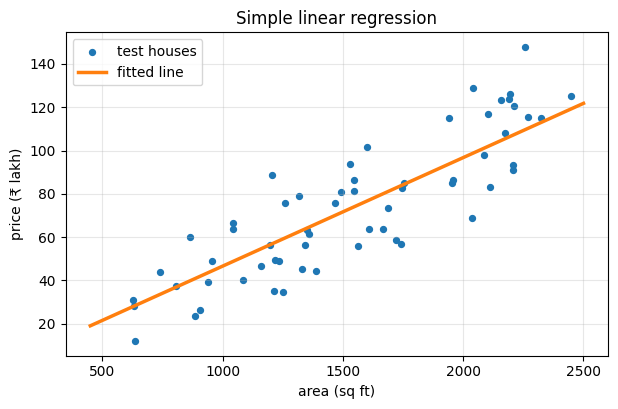

In [5]:
slr = LinearRegression()
slr.fit(X_train[["area_sqft"]], y_train)     # double brackets keep X 2-D: (n_samples, 1)

grid = pd.DataFrame({"area_sqft": np.linspace(450, 2500, 50)})
plt.scatter(X_test["area_sqft"], y_test, s=18, label="test houses")
plt.plot(grid["area_sqft"], slr.predict(grid), color="C1", lw=2.5, label="fitted line")
plt.xlabel("area (sq ft)"); plt.ylabel("price (₹ lakh)"); plt.legend(); plt.title("Simple linear regression")
plt.show()

**Questions**
1. Why does scikit-learn insist that `X` is 2-D even when there is a single feature?
2. Looking at the plot, name one reason the points do not lie exactly on the line.

**Reflection:** is area alone a good predictor? What would you check next?
**Answers**
1. Estimators take a matrix of shape `(n_samples, n_features)`. `X_train["area_sqft"]` is a 1-D Series; `X_train[["area_sqft"]]` is a one-column DataFrame.
2. Price also depends on other features (distance, age, …) and on random noise; one feature cannot capture everything.

**Common mistake:** `slr.fit(X_train["area_sqft"], y_train)` → `ValueError: Expected 2D array`.

---
## A3 · Interpreting slope and intercept
**Objective:** translate `coef_` and `intercept_` into plain language.

**Concept reminder:** $b_1$ = change in predicted $y$ for a one-unit increase in $x$. $b_0$ = predicted $y$ when $x=0$.

**Instructions**
1. Print `slr.coef_[0]` and `slr.intercept_`.
2. Compute *by hand* (using the printed numbers) the predicted price of a 1,200 sq ft house, then confirm with `slr.predict`.

In [6]:
b1 = slr.coef_[0]
b0 = slr.intercept_
print(f"slope b1     = {b1:.5f} ₹ lakh per sq ft")
print(f"intercept b0 = {b0:.3f} ₹ lakh")

slope b1     = 0.05016 ₹ lakh per sq ft
intercept b0 = -3.572 ₹ lakh


In [7]:
manual_1200 = b0 + b1 * 1200
model_1200 = slr.predict(pd.DataFrame({"area_sqft": [1200]}))[0]
print(f"manual: {manual_1200:.3f}   model: {model_1200:.3f}   equal: {np.isclose(manual_1200, model_1200)}")

manual: 56.615   model: 56.615   equal: True


**Questions**
1. Complete the sentence: "Each additional 100 sq ft is associated with a predicted price change of ___ ₹ lakh."
2. Interpret the intercept. Is it meaningful here?
3. Can we conclude that adding area to a house *causes* this price increase?
**Answers** (numbers from the executed cell above)
1. 100 × b1 ≈ **5.0 ₹ lakh** per 100 sq ft (b1 ≈ 0.0502).
2. b0 is the predicted price of a 0 sq ft house. No real house has zero area, so it is an *extrapolation* that anchors the line, not a real-world price. Here it is ≈ −3.6 ₹ lakh — a negative "price", which is a clear reminder not to read it literally.
3. No. Regression measures association in this data. In a single-feature model, area can also "absorb" the effect of correlated features such as bedrooms — revisit this in A7.

**Common mistake:** reading `coef_` as a scalar — it is an array, one entry per feature.

---
## A4 · Manual OLS — compute the line yourself
**Objective:** reproduce the least-squares slope and intercept using only NumPy and the formulas from class.

$$b_1=\frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2}\qquad b_0=\bar y-b_1\bar x$$

**Dataset:** `regression_manual_example.csv` — 5 deliveries: distance (km) and delivery time (min). *A teaching example: we fit and evaluate on the same five points, which shows the arithmetic but says nothing about performance on new data.*

**Expected output:** a table of deviations; slope 2.1 and intercept 8.4.

In [8]:
manual = pd.read_csv(DATA / "regression_manual_example.csv")
x = manual["distance_km"].to_numpy(dtype=float)
y = manual["delivery_min"].to_numpy(dtype=float)
manual

,distance_km,delivery_min
0,2,12
1,4,18
2,6,20
3,8,26
4,10,29


In [9]:
x_bar = x.mean()
y_bar = y.mean()
dx = x - x_bar
dy = y - y_bar
numerator = np.sum(dx * dy)
denominator = np.sum(dx ** 2)
b1_manual = numerator / denominator
b0_manual = y_bar - b1_manual * x_bar
table = pd.DataFrame({"x": x, "y": y, "x - x̄": dx, "y - ȳ": dy,
                      "(x-x̄)(y-ȳ)": dx * dy, "(x-x̄)²": dx ** 2})
display(table)
print(f"x̄ = {x_bar}, ȳ = {y_bar}, numerator = {numerator}, denominator = {denominator}")
print(f"b1 = {b1_manual:.4f}, b0 = {b0_manual:.4f}")

,x,y,x - x̄,y - ȳ,(x-x̄)(y-ȳ),(x-x̄)²
0,2.0,12.0,-4.0,-9.0,36.0,16.0
1,4.0,18.0,-2.0,-3.0,6.0,4.0
2,6.0,20.0,0.0,-1.0,-0.0,0.0
3,8.0,26.0,2.0,5.0,10.0,4.0
4,10.0,29.0,4.0,8.0,32.0,16.0


x̄ = 6.0, ȳ = 21.0, numerator = 84.0, denominator = 40.0
b1 = 2.1000, b0 = 8.4000


In [10]:
y_hat = b0_manual + b1_manual * x
residuals = y - y_hat
print("predictions:", np.round(y_hat, 3))
print("residuals  :", np.round(residuals, 3), " | sum =", round(residuals.sum(), 10))
print("SSE        :", round(np.sum(residuals ** 2), 4))

# Verification against scikit-learn and against a least-squares matrix solver
check = LinearRegression().fit(x.reshape(-1, 1), y)
X_design = np.column_stack([np.ones_like(x), x])          # n x 2 design matrix [1, x]
beta_lstsq, *_ = np.linalg.lstsq(X_design, y, rcond=None)
print("sklearn  :", round(check.intercept_, 4), round(check.coef_[0], 4))
print("lstsq    :", np.round(beta_lstsq, 4))
assert np.isclose(check.coef_[0], b1_manual) and np.isclose(check.intercept_, b0_manual)

predictions:

 [12.6 16.8 21.  25.2 29.4]
residuals  : [-0.6  1.2 -1.   0.8 -0.4]  | sum = 0.0
SSE        : 3.6
sklearn  : 8.4 2.1
lstsq    : [8.4 2.1]


**Questions**
1. The residuals add up to (numerically) zero. Is that a coincidence? Use the derivative $\partial SSE/\partial b_0 = 0$ to explain.
2. Which single observation has the largest absolute residual?
3. If every delivery time were increased by 5 minutes, how would $b_1$ and $b_0$ change?

**Reflection:** which step of the calculation would be most error-prone by hand?
**Answers**
1. Not a coincidence. Setting $\partial SSE/\partial b_0 = -2\sum(y_i-b_0-b_1x_i)=0$ forces $\sum e_i = 0$ whenever the model has an intercept.
2. x = 4 km: residual +1.2 min.
3. $b_1$ is unchanged (every $y_i-\bar y$ is unchanged); $b_0$ rises by 5 (because $\bar y$ rises by 5).

**Common mistakes:** using $\sum x_iy_i$ instead of the centred products; dividing by $n$ in one sum but not the other (the $n$'s cancel only if used in both).

---
## A5 · Gradient Descent — complete the update steps
**Objective:** implement batch gradient descent for $\hat y = wx+b$ and watch the cost fall.

$$J(w,b)=\frac{1}{2n}\sum(y_i-\hat y_i)^2,\quad \frac{\partial J}{\partial w}=-\frac1n\sum(y_i-\hat y_i)x_i,\quad \frac{\partial J}{\partial b}=-\frac1n\sum(y_i-\hat y_i)$$
$$w \leftarrow w-\alpha\,\partial J/\partial w,\qquad b \leftarrow b-\alpha\,\partial J/\partial b$$

**Dataset:** the class example $x=[1,2,3]$, $y=[2,4,5]$, start $w=b=0$, $\alpha=0.1$.

**Expected output:** iteration 0 cost 7.5, iteration 1 cost ≈ 1.5098, iteration 2 cost ≈ 0.3217 — the same numbers we computed by hand.

In [11]:
x_gd = np.array([1.0, 2.0, 3.0])
y_gd = np.array([2.0, 4.0, 5.0])

def compute_cost(w, b, x, y):
    n = len(x)
    residuals = y - (w * x + b)
    return np.sum(residuals ** 2) / (2 * n)

def compute_gradients(w, b, x, y):
    n = len(x)
    residuals = y - (w * x + b)
    dJ_dw = -np.sum(residuals * x) / n
    dJ_db = -np.sum(residuals) / n
    return dJ_dw, dJ_db

def gradient_descent(x, y, w=0.0, b=0.0, alpha=0.1, iterations=100):
    history = []
    for it in range(iterations + 1):
        cost = compute_cost(w, b, x, y)
        dJ_dw, dJ_db = compute_gradients(w, b, x, y)
        history.append({"iteration": it, "w": w, "b": b, "cost": cost, "dJ_dw": dJ_dw, "dJ_db": dJ_db})
        w = w - alpha * dJ_dw
        b = b - alpha * dJ_db
    return pd.DataFrame(history)

,iteration,w,b,cost,dJ_dw,dJ_db
0,0,0.0000,0.0000,7.5000,-8.3333,-3.6667
1,1,0.8333,0.3667,1.5098,-3.7111,-1.6333
2,2,1.2044,0.5300,0.3217,-1.6526,-0.7278
3,3,1.3697,0.6028,0.0861,-0.7358,-0.3245


after 200 iterations: {'w': 1.5002, 'b': 0.6662, 'cost': 0.0278}
least-squares solution: w = 1.5  b = 0.6667


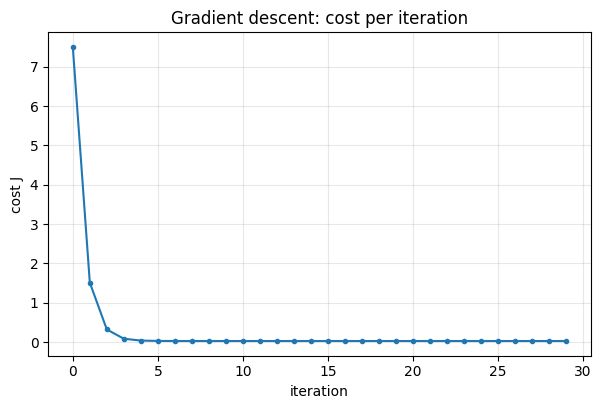

In [12]:
hist = gradient_descent(x_gd, y_gd, alpha=0.1, iterations=200)
display(hist.head(4).round(4))
print("after 200 iterations:", hist.iloc[-1][["w", "b", "cost"]].round(4).to_dict())

ols = LinearRegression().fit(x_gd.reshape(-1, 1), y_gd)
print("least-squares solution: w =", round(ols.coef_[0], 4), " b =", round(ols.intercept_, 4))

plt.plot(hist["iteration"][:30], hist["cost"][:30], marker="o", ms=3)
plt.xlabel("iteration"); plt.ylabel("cost J"); plt.title("Gradient descent: cost per iteration"); plt.show()

In [13]:
# Experiment: change the learning rate and compare
for alpha in [0.01, 0.1, 0.3, 0.37]:
    h = gradient_descent(x_gd, y_gd, alpha=alpha, iterations=50)
    print(f"alpha={alpha:<5} final cost after 50 iterations = {h['cost'].iloc[-1]:.6g}")

alpha=0.01  final cost after 50 iterations = 0.0526266
alpha=0.1   final cost after 50 iterations = 0.0277785
alpha=0.3   final cost after 50 iterations = 0.0277778
alpha=0.37  final cost after 50 iterations = 1210.71


**Questions**
1. At iteration 0 both gradients are negative. Why does that make $w$ and $b$ *increase*?
2. Which learning rate diverges? Explain what happens to the updates.
3. scikit-learn's `LinearRegression` gave the answer instantly. Does it run this loop internally?

**Reflection:** when would you prefer an iterative method over the closed-form solution?
**Answers**
1. The update is $w - \alpha\cdot(\text{negative})$ = $w$ + something. A negative gradient means the cost *decreases* as $w$ increases, so we step in that direction.
2. α = 0.37 diverges (cost explodes). For this data, batch GD is stable only for α < 2/λ_max ≈ 0.36, where λ_max ≈ 5.55 is the largest eigenvalue of the cost's curvature matrix; α = 0.3 still converges but zig-zags. Each step overshoots the minimum by more than it corrects, so the parameters oscillate with growing amplitude.
3. No. `LinearRegression` solves the least-squares problem directly with a linear-algebra solver (SciPy's least-squares routine), not with gradient descent.
4. (Reflection) Iterative methods scale to very large data, streaming data, and models with no closed-form solution (e.g., most neural networks, Lasso).

**Common mistakes:** sign errors (`w + alpha * dJ_dw`); updating `w` and then using the *new* `w` to compute the gradient for `b` in the same step (both gradients must use the old values — our function computes them together).

---
## A6 · Evaluation metrics
**Objective:** compute MAE, MSE, RMSE and R² by hand, confirm with scikit-learn, then evaluate the A2 model on **held-out** houses.

| metric | formula | units |
|---|---|---|
| MAE | $\frac1n\sum|y-\hat y|$ | same as y |
| MSE | $\frac1n\sum(y-\hat y)^2$ | y² |
| RMSE | $\sqrt{MSE}$ | same as y |
| R² | $1-SSE/SST$ | none |

In [14]:
def regression_report(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float); y_pred = np.asarray(y_pred, dtype=float)
    errors = y_true - y_pred
    mae = np.mean(np.abs(errors))
    mse = np.mean(errors ** 2)
    rmse = np.sqrt(mse)
    sse = np.sum(errors ** 2)
    sst = np.sum((y_true - y_true.mean()) ** 2)
    r2 = 1 - sse / sst
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

ours = regression_report(y, y_hat)          # teaching example from A4 (training points!)
theirs = {"MAE": mean_absolute_error(y, y_hat), "MSE": mean_squared_error(y, y_hat),
          "RMSE": np.sqrt(mean_squared_error(y, y_hat)), "R2": r2_score(y, y_hat)}
pd.DataFrame({"manual": ours, "sklearn": theirs}).round(4)

,manual,sklearn
MAE,0.8000,0.8000
MSE,0.7200,0.7200
RMSE,0.8485,0.8485
R2,0.9800,0.9800


In [15]:
# Outlier experiment: identical errors except one large miss
actual  = np.array([10, 12, 15, 20, 25.0])
model_P = np.array([11, 11, 16, 19, 26.0])     # every error = 1
model_Q = np.array([11, 11, 16, 19, 35.0])     # four errors = 1, one error = 10
pd.DataFrame({"P": regression_report(actual, model_P), "Q": regression_report(actual, model_Q)}).round(3)

,P,Q
MAE,1.000,2.800
MSE,1.000,20.800
RMSE,1.000,4.561
R2,0.966,0.303


In [16]:
slr_test_pred = slr.predict(X_test[["area_sqft"]])
slr_scores = regression_report(y_test, slr_test_pred)
pd.Series(slr_scores).round(3)

MAE      13.394
MSE     258.677
RMSE     16.083
R2        0.739
dtype: float64

**Questions**
1. In the outlier experiment MAE grew 2.8×. By what factor did MSE grow? Why so much more?
2. The house model's RMSE is in what units? Express it as a sentence a manager would understand.
3. Could R² on the test set ever be negative? What would that mean?

**Reflection:** which metric would you report to a non-technical stakeholder, and which would you use to choose between models?
**Answers**
1. MSE: 1 → 20.8 (×20.8). Squaring turns an error of 10 into 100, so one large miss dominates. RMSE: 1 → 4.56.
2. ₹ lakh. "Using area alone, predictions for unseen houses are off by about ₹13 lakh on average" (MAE ≈ 13.4; RMSE ≈ 16.1 — see output). RMSE weights big misses more, so it is ≥ MAE.
3. Yes. R² < 0 means the model's squared error on that data is larger than simply predicting the mean of the evaluated targets — worse than the trivial baseline.
4. (Reflection) MAE / RMSE in ₹ for stakeholders; for model selection use a metric aligned with the cost of errors (often RMSE/MSE), computed by cross-validation or on held-out data.

**Common mistakes:** passing arguments as `(y_pred, y_true)` — harmless for MAE/MSE but **wrong for R²**, which is not symmetric.

---
## A7 · Multiple Linear Regression
**Objective:** use all six features: $\hat y = b_0 + b_1x_1 + \dots + b_6x_6$, interpret coefficients and compare with A2 **on the same test set**.

**Concept reminder:** each $b_j$ is the change in predicted price per unit of $x_j$ **holding the other features fixed**. Coefficients are in different units, so their sizes are not directly comparable.

In [17]:
mlr = LinearRegression().fit(X_train, y_train)
coef_table = pd.DataFrame({"feature": FEATURES, "coefficient": mlr.coef_,
                           "unit": ["₹ lakh per sq ft", "₹ lakh per bedroom", "₹ lakh per year",
                                    "₹ lakh per km", "₹ lakh per floor", "₹ lakh (has vs no parking)"]})
display(coef_table.round(4))
print("intercept:", round(mlr.intercept_, 3))

,feature,coefficient,unit
0,area_sqft,0.0497,₹ lakh per sq ft
1,bedrooms,1.9273,₹ lakh per bedroom
2,property_age_yrs,-0.3826,₹ lakh per year
3,distance_city_km,-1.4614,₹ lakh per km
4,floor_number,0.2275,₹ lakh per floor
5,parking,4.0721,₹ lakh (has vs no parking)


intercept: 17.133


In [18]:
def adjusted_r2(r2, n, p):
    # defined only when n - p - 1 > 0
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

mlr_scores = regression_report(y_test, mlr.predict(X_test))
mlr_scores["Adj R2"] = adjusted_r2(mlr_scores["R2"], n=len(y_test), p=len(FEATURES))
comparison = pd.DataFrame({"SLR (area only)": slr_scores, "MLR (6 features)": mlr_scores}).round(3)
comparison

,SLR (area only),MLR (6 features)
MAE,13.394,4.375
MSE,258.677,33.114
RMSE,16.083,5.754
R2,0.739,0.967
Adj R2,NaN,0.963


In [19]:
# Predict one new house — first by hand from coefficients, then with the model
new_house = pd.DataFrame([{"area_sqft": 1200, "bedrooms": 2, "property_age_yrs": 10,
                           "distance_city_km": 8, "floor_number": 5, "parking": 1}])
by_hand = mlr.intercept_ + np.sum(mlr.coef_ * new_house.iloc[0].to_numpy())
print(f"by hand: {by_hand:.3f}   model: {mlr.predict(new_house)[0]:.3f}")

display(house[FEATURES].corr().round(2))

by hand: 70.285   model: 70.285


,area_sqft,bedrooms,property_age_yrs,distance_city_km,floor_number,parking
area_sqft,1.00,0.82,0.03,0.09,-0.08,0.22
bedrooms,0.82,1.00,0.05,0.11,-0.05,0.19
property_age_yrs,0.03,0.05,1.00,-0.04,0.01,0.02
distance_city_km,0.09,0.11,-0.04,1.00,0.06,-0.04
floor_number,-0.08,-0.05,0.01,0.06,1.00,-0.13
parking,0.22,0.19,0.02,-0.04,-0.13,1.00


**Questions**
1. Interpret the `distance_city_km` coefficient in one sentence, including "holding other features fixed".
2. Compare the area coefficient here with A2. Why *can* adding a correlated feature like `bedrooms` change a coefficient, even though here the change is small?
3. `area_sqft` and `bedrooms` have correlation ≈ 0.8. What problem can this cause for coefficient interpretation?
4. Does the large area coefficient mean area is the "most important" feature? Why/why not?
**Answers**
1. "Holding area, bedrooms, age, floor and parking fixed, each extra km from the centre is associated with ≈ ₹1.46 lakh lower predicted price."
2. A2: 0.0502, A7: 0.0497 per sq ft. In a one-feature model the slope can carry part of the effect of omitted correlated features (larger houses have more bedrooms); with bedrooms included, area's coefficient measures its association *for the same number of bedrooms*. Here bedrooms' own effect is modest and sampling noise is comparable, so the shift is small — in other data it can even flip sign.
3. Multicollinearity: the model struggles to separate the two effects, so their coefficients can be unstable (large standard errors; can change a lot between samples) even if predictions stay good.
4. No. 0.05 per **sq ft** vs 1.9 per **bedroom** — units differ. Compare importance only after standardising features (see A10) or with other methods; even then, importance ≠ causation.

---
## A8 · Polynomial Regression
**Objective:** build polynomial features by hand, then with `PolynomialFeatures`, and compare degrees on curved data.

**Concept reminder:** $\hat y=b_0+b_1x+b_2x^2$ is curved in $x$ but **linear in the coefficients** — so ordinary least squares still fits it once we add the column $x^2$.

**Dataset:** `polynomial_regression.csv` — speed (km/h) vs fuel efficiency (km/l), 150 synthetic trips.

In [20]:
# Step 1 — by hand on three values
x_small = np.array([[1.0], [2.0], [3.0]])
manual_features = np.column_stack([x_small[:, 0], x_small[:, 0] ** 2])
sk_features = PolynomialFeatures(degree=2, include_bias=False).fit_transform(x_small)
print(manual_features); print(sk_features)
print("identical:", np.allclose(manual_features, sk_features))

[[1. 1.]
 [2. 4.]
 [3. 9.]]
[[1. 1.]
 [2. 4.]
 [3. 9.]]
identical: True


In [21]:
poly_df = pd.read_csv(DATA / "polynomial_regression.csv")
Xp_train, Xp_test, yp_train, yp_test = train_test_split(
    poly_df[["speed_kmph"]], poly_df["fuel_efficiency_kmpl"], test_size=0.3, random_state=SEED)

def poly_model(degree):
    # Order matters: create powers -> scale them (keeps high powers numerically sane) -> fit OLS
    return make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), LinearRegression())

rows = []
for d in [1, 2, 3, 15]:
    model = poly_model(d).fit(Xp_train, yp_train)
    train_mse = mean_squared_error(yp_train, model.predict(Xp_train))
    test_mse = mean_squared_error(yp_test, model.predict(Xp_test))
    rows.append({"degree": d, "train MSE": train_mse, "test MSE": test_mse})
pd.DataFrame(rows).round(3)

,degree,train MSE,test MSE
0,1,4.112,6.360
1,2,0.761,0.947
2,3,0.761,0.949
3,15,0.686,1.153


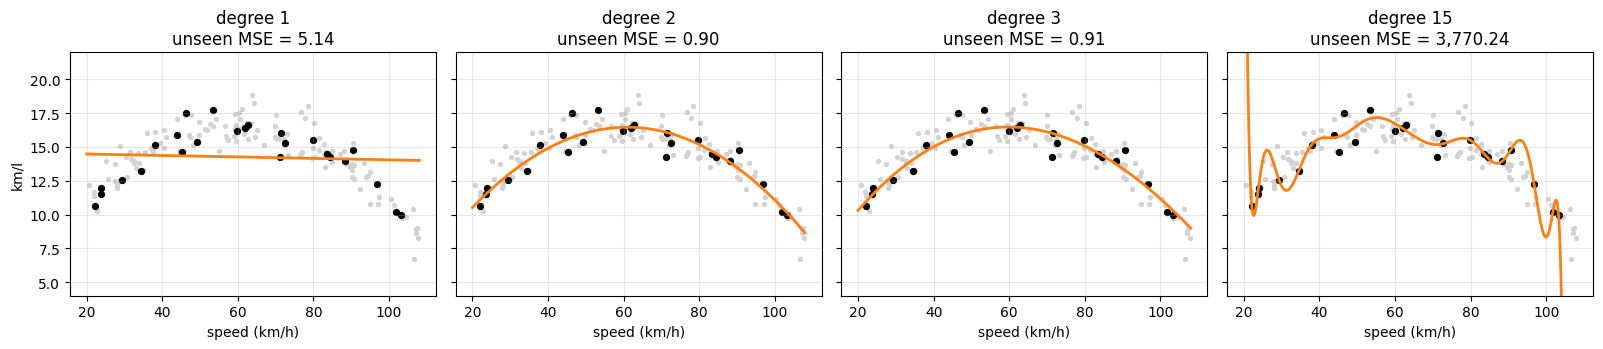

In [22]:
# Overfitting is easiest to see when training data are scarce: fit on only 25 trips
small = poly_df.sample(25, random_state=3); rest = poly_df.drop(small.index)
grid = pd.DataFrame({"speed_kmph": np.linspace(20, 108, 400)})
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, d in zip(axes, [1, 2, 3, 15]):
    m = poly_model(d).fit(small[["speed_kmph"]], small["fuel_efficiency_kmpl"])
    ax.scatter(rest["speed_kmph"], rest["fuel_efficiency_kmpl"], s=8, color="lightgray", label="unseen")
    ax.scatter(small["speed_kmph"], small["fuel_efficiency_kmpl"], s=18, color="k", label="training")
    ax.plot(grid["speed_kmph"], m.predict(grid), color="C1", lw=2)
    unseen = mean_squared_error(rest["fuel_efficiency_kmpl"], m.predict(rest[["speed_kmph"]]))
    ax.set_title(f"degree {d}\nunseen MSE = {unseen:,.2f}"); ax.set_ylim(4, 22); ax.set_xlabel("speed (km/h)")
axes[0].set_ylabel("km/l"); plt.tight_layout(); plt.show()

**Questions**
1. Which degree underfits? Which overfits? What evidence in the table/plots supports each answer?
2. Why do we put `StandardScaler` *after* `PolynomialFeatures` here?
3. A friend says "degree 15 has the lowest training error, so it's the best model." Respond.
**Answers**
1. Degree 1 underfits (high train *and* test MSE — a line cannot bend). Degree 15 overfits (lowest train MSE, test MSE rises; with 25 points its curve swings wildly and unseen MSE explodes). Degrees 2–3 are about right.
2. Powers like speed¹⁵ are astronomically large and nearly collinear with each other; scaling the *generated* columns keeps the least-squares problem numerically stable. Inside the pipeline the scaler is fitted on training rows only.
3. Training error always falls (or stays equal) as degree rises because higher-degree models contain lower-degree ones. Choose by validation/CV error, not training error.

---
## A9 · Bias–variance: training vs validation behaviour
**Objective:** pick a degree with **5-fold cross-validation on the training set only**, and observe variance directly by refitting on many small samples.

degree with lowest CV MSE: 2


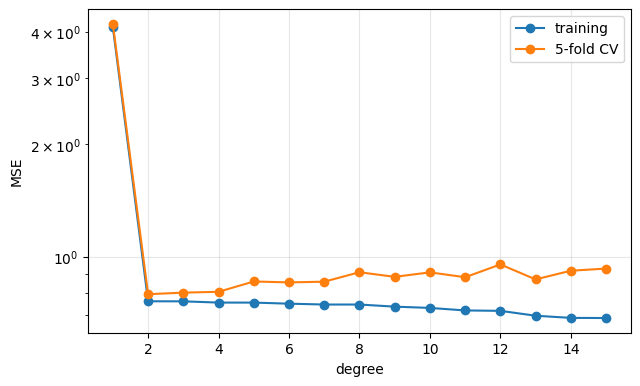

test MSE of the chosen degree (used once): 0.947


In [23]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
records = []
for d in range(1, 16):
    train_mse = mean_squared_error(yp_train, poly_model(d).fit(Xp_train, yp_train).predict(Xp_train))
    cv_mse = -cross_val_score(poly_model(d), Xp_train, yp_train, cv=cv,
                              scoring="neg_mean_squared_error").mean()
    records.append({"degree": d, "train MSE": train_mse, "CV MSE": cv_mse})
curve = pd.DataFrame(records)
best_degree = int(curve.loc[curve["CV MSE"].idxmin(), "degree"])
print("degree with lowest CV MSE:", best_degree)
plt.plot(curve["degree"], curve["train MSE"], "o-", label="training")
plt.plot(curve["degree"], curve["CV MSE"], "o-", label="5-fold CV")
plt.yscale("log"); plt.xlabel("degree"); plt.ylabel("MSE"); plt.legend(); plt.show()

final_poly = poly_model(best_degree).fit(Xp_train, yp_train)
print("test MSE of the chosen degree (used once):", round(mean_squared_error(yp_test, final_poly.predict(Xp_test)), 3))

In [24]:
# Variance made visible: refit each model on 30 different random samples of 25 trips,
# and record its prediction at speed = 100 km/h (near the edge of the data).
query = pd.DataFrame({"speed_kmph": [100.0]})
spread = {}
for d in [1, 2, 9]:
    preds = []
    for rep in range(30):
        s = poly_df.sample(25, random_state=100 + rep)
        preds.append(poly_model(d).fit(s[["speed_kmph"]], s["fuel_efficiency_kmpl"]).predict(query)[0])
    spread[f"degree {d}"] = {"mean prediction": np.mean(preds), "std of predictions": np.std(preds)}
pd.DataFrame(spread).T.round(3)

,mean prediction,std of predictions
degree 1,13.493,0.933
degree 2,10.952,0.362
degree 9,8.673,13.372


**Questions**
1. Describe the shape of the two curves. Where is the model underfitting, and where is it overfitting?
2. In the resampling table, which degree has the largest spread of predictions? Which term of the bias–variance decomposition does that spread illustrate?
3. Why is it wrong to pick the degree by looking at the test MSE of every degree?

**Reflection:** state the bias–variance trade-off in one sentence of your own.
**Answers**
1. Training MSE falls steadily with degree. CV MSE drops sharply from degree 1 to 2 (underfitting → good fit) and then creeps up for high degrees (overfitting). Degree 2 has the lowest CV MSE.
2. Degree 9: its predictions change the most from sample to sample → **variance**. Degree 1 is fairly stable but systematically off → **bias**: because the data are synthetic we know the noise-free value at 100 km/h is 4 + 42 − 35 = 11.0 km/l; degree 1 averages ≈ 13.5, degree 2 ≈ 11.0. Note: this is an illustration with resamples, not a computed decomposition from a single split.
3. The test set would then have been used for model selection, so its score becomes optimistically biased and no longer estimates performance on new data.

---
## A10 · Ridge and Lasso (introduction)
**Objective:** compare coefficients of Linear, Ridge and Lasso regression on the house data, and see regularisation tame an overfitting polynomial.

**Conventions in scikit-learn** (different from the classroom "SSE + penalty" form, so α values are *not* interchangeable):
- `Ridge`: $\|y-X\beta\|^2_2+\alpha\|\beta\|^2_2$  (intercept not penalised)
- `Lasso`: $\frac{1}{2n}\|y-X\beta\|^2_2+\alpha\|\beta\|_1$  (intercept not penalised)

Penalties depend on coefficient size, which depends on feature units → **always scale inside a Pipeline**.

In [25]:
models = {
    "Linear": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge (alpha=10)": make_pipeline(StandardScaler(), Ridge(alpha=10)),
    "Lasso (alpha=1.5)": make_pipeline(StandardScaler(), Lasso(alpha=1.5)),
}
coefs, scores = {}, {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    coefs[name] = pipe[-1].coef_                      # coefficients on standardised features
    scores[name] = regression_report(y_test, pipe.predict(X_test))
display(pd.DataFrame(coefs, index=FEATURES).round(3))
display(pd.DataFrame(scores).round(3))

,Linear,Ridge (alpha=10),Lasso (alpha=1.5)
area_sqft,28.143,25.225,27.580
bedrooms,2.014,4.099,0.834
property_age_yrs,-4.039,-3.827,-2.233
distance_city_km,-12.423,-11.834,-10.600
floor_number,1.385,1.296,0.000
parking,2.035,2.268,0.634


,Linear,Ridge (alpha=10),Lasso (alpha=1.5)
MAE,4.375,4.500,5.794
MSE,33.114,34.640,53.905
RMSE,5.754,5.886,7.342
R2,0.967,0.965,0.946


In [26]:
# Choose Ridge's alpha by cross-validation on the training set (never on the test set)
for alpha in [0.1, 1, 10, 100, 1000]:
    rmse = -cross_val_score(make_pipeline(StandardScaler(), Ridge(alpha=alpha)), X_train, y_train,
                            cv=cv, scoring="neg_root_mean_squared_error").mean()
    print(f"Ridge alpha={alpha:<6} CV RMSE = {rmse:.3f}")

Ridge alpha=0.1    CV RMSE = 6.355
Ridge alpha=1      CV RMSE = 6.357
Ridge alpha=10     CV RMSE = 6.681
Ridge alpha=100    CV RMSE = 11.785
Ridge alpha=1000   CV RMSE = 25.164


In [27]:
# Regularisation rescuing the degree-15 polynomial fitted on 25 trips
for name, last in [("OLS", LinearRegression()), ("Ridge alpha=1", Ridge(alpha=1.0))]:
    m = make_pipeline(PolynomialFeatures(15, include_bias=False), StandardScaler(), last)
    m.fit(small[["speed_kmph"]], small["fuel_efficiency_kmpl"])
    print(f"degree 15 + {name:<14} unseen MSE = {mean_squared_error(rest['fuel_efficiency_kmpl'], m.predict(rest[['speed_kmph']])):,.3f}")

degree 15 + OLS            unseen MSE = 3,770.237
degree 15 + Ridge alpha=1  unseen MSE = 1.203


**Questions**
1. Which coefficient did Lasso set exactly to zero? Why is that feature a natural candidate?
2. Compare the Ridge and Linear coefficients for `area_sqft` and `bedrooms`. What did Ridge do with these two correlated features?
3. Why would fitting Ridge **without** scaling be a problem in this dataset?
4. Explain, using the penalty term, why the degree-15 Ridge model behaves so much better on unseen data.
5. Which Ridge α does cross-validation prefer for the house data, and what does that tell you?
**Answers**
1. `floor_number` → 0. It has the weakest association with price (true synthetic effect is small relative to noise), so the L1 penalty's constant pull outweighs its small benefit in fit.
2. Ridge shrank area (28.1 → 25.2) and *raised* bedrooms (2.0 → 4.1): with correlated features the L2 penalty prefers to share the effect across them rather than put it all on one.
3. Coefficients are in feature units: area's coefficient per sq ft is tiny, bedrooms' is large. Unscaled, the same α would barely penalise area but heavily penalise bedrooms — the penalty would depend on arbitrary units.
4. Wild degree-15 curves need huge, opposite-signed coefficients. The L2 penalty makes those expensive, so the optimiser accepts a slightly worse training fit for much smaller coefficients — a smoother curve with lower variance.

5. The smallest α (≈ plain OLS) — with 240 rows, 6 features and modest noise there is little variance to remove, so regularisation does not help here. It pays off when models are flexible relative to the data (the degree-15 example) or when p is large compared with n.

**Common mistake:** comparing `Lasso(alpha=1.5)` with the classroom formula's α = 1.5 — the objectives are scaled differently.

---
## A11 · Final Challenge — delivery time prediction
**Objective:** build, evaluate and improve a regression model **independently**. (Full brief and marking rubric: `08_Final_Regression_Challenge.docx`.)

**Dataset:** `delivery_time_challenge.csv` — 260 synthetic food deliveries. Target: `delivery_time_min`.

**Your steps**
1. Load and inspect (shape, dtypes, missing values, summary).
2. Identify features and target; split with `test_size=0.2, random_state=42`.
3. Train a `LinearRegression` baseline; report MAE, MSE, RMSE, R² on the test set.
4. Interpret two coefficients in plain language with units.
5. Propose **one** alternative (a transformation, polynomial terms, or regularisation). Compare with the baseline using 5-fold CV RMSE on the **training set**.
6. Evaluate only your chosen final model on the test set.
7. Comment on any sign of overfitting (compare training vs CV error).
8. Manual question: using your baseline coefficients, compute the prediction for one test row by hand.

In [28]:
deliv = pd.read_csv(DATA / "delivery_time_challenge.csv")
print(deliv.shape); print(deliv.isna().sum().sum(), "missing values")
display(deliv.describe().T.round(2))

D_TARGET = "delivery_time_min"
D_FEATURES = [c for c in deliv.columns if c != D_TARGET]
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    deliv[D_FEATURES], deliv[D_TARGET], test_size=0.2, random_state=SEED)

baseline = LinearRegression().fit(Xd_train, yd_train)
display(pd.Series(baseline.coef_, index=D_FEATURES, name="coefficient").round(3))
print("intercept:", round(baseline.intercept_, 3))
display(pd.Series(regression_report(yd_test, baseline.predict(Xd_test)), name="baseline (test)").round(3))

(260, 6)
0 missing values


,count,mean,std,min,25%,50%,75%,max
distance_km,260.0,7.78,4.19,0.55,4.10,8.03,11.46,14.93
items_in_order,260.0,4.62,2.37,1.00,2.00,5.00,7.00,8.00
traffic_index,260.0,5.13,2.71,0.00,2.90,5.20,7.40,10.00
restaurant_prep_min,260.0,17.55,7.09,5.00,11.75,17.00,24.00,30.00
raining,260.0,0.29,0.45,0.00,0.00,0.00,1.00,1.00
delivery_time_min,260.0,49.38,12.60,16.30,41.48,49.50,57.30,85.40


distance_km            2.089
items_in_order         0.914
traffic_index          2.409
restaurant_prep_min    0.591
raining                5.459
Name: coefficient, dtype: float64

intercept: 4.496


MAE      2.769
MSE     11.941
RMSE     3.456
R2       0.927
Name: baseline (test), dtype: float64

In [29]:
# Residual check suggests curvature in traffic -> add traffic_index^2 only (ColumnTransformer)
traffic_sq = Pipeline([
    ("features", ColumnTransformer([("traffic_poly", PolynomialFeatures(2, include_bias=False), ["traffic_index"])],
                                   remainder="passthrough")),
    ("ols", LinearRegression())])
candidates = {
    "baseline linear": LinearRegression(),
    "+ traffic²": traffic_sq,
    "full degree-3 polynomial": make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(), LinearRegression()),
    "degree-3 + Ridge(1)": make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(), Ridge(alpha=1.0)),
}
rows = []
for name, m in candidates.items():
    train_rmse = np.sqrt(mean_squared_error(yd_train, m.fit(Xd_train, yd_train).predict(Xd_train)))
    cv_rmse = -cross_val_score(m, Xd_train, yd_train, cv=cv, scoring="neg_root_mean_squared_error").mean()
    rows.append({"model": name, "train RMSE": train_rmse, "5-fold CV RMSE": cv_rmse})
display(pd.DataFrame(rows).round(3))

final = traffic_sq.fit(Xd_train, yd_train)          # chosen by CV, evaluated once on test
display(pd.Series(regression_report(yd_test, final.predict(Xd_test)), name="+ traffic² (test)").round(3))

# Manual prediction check for the first test row (baseline model)
row = Xd_test.iloc[0]
manual_pred = baseline.intercept_ + np.sum(baseline.coef_ * row.to_numpy())
print(row.to_dict())
print(f"manual = {manual_pred:.3f}, model = {baseline.predict(Xd_test.iloc[[0]])[0]:.3f}")

,model,train RMSE,5-fold CV RMSE
0,baseline linear,3.558,3.624
1,+ traffic²,2.839,2.922
2,full degree-3 polynomial,2.576,3.664
3,degree-3 + Ridge(1),2.682,3.191


MAE      2.675
MSE     10.553
RMSE     3.249
R2       0.936
Name: + traffic² (test), dtype: float64

{'distance_km': 7.7, 'items_in_order': 3.0, 'traffic_index': 5.5, 'restaurant_prep_min': 16.0, 'raining': 0.0}
manual = 46.025, model = 46.025


**Interpretation (trainer key)**
- *Coefficients (baseline):* each extra km adds ≈ 2.09 min; rain adds ≈ 5.46 min, other features held fixed.
- *Model choice:* adding traffic² cuts CV RMSE from ≈ 3.62 to ≈ 2.92 min → the effect of traffic is curved (heavy traffic hurts disproportionately).
- *Overfitting:* the full degree-3 polynomial has the lowest *training* RMSE (≈ 2.58) but CV RMSE ≈ 3.66, worse than the simpler model — overfitting. Ridge(1) reduces that gap (CV ≈ 3.19) but the targeted traffic² model is still best.
- *Test set* was used only once, for the chosen model (RMSE ≈ 3.25, R² ≈ 0.94).

---
### End of notebook — summary
| idea | where you used it |
|---|---|
| OLS line & residuals | A2–A4 |
| Gradient descent | A5 |
| MAE / MSE / RMSE / R² | A6 |
| Multiple regression & interpretation | A7 |
| Polynomial features | A8 |
| Bias–variance, cross-validation | A9 |
| Ridge / Lasso | A10 |